# CEUB - Centro Universitário de Brasília
## Disciplina: Fundamentos de Big Data
### Professor: Klayton R. Castro
### Avaliação 01 – Prática: Questão 2 (Análise Exploratória de Dados)

---

### Enunciado da Questão 2 (Valor: 2,0 pontos)
> Realize uma análise exploratória do **Censo da Educação Superior 2022**, utilizando o **MongoDB** como repositório. O objetivo é aplicar operações de agregação e representar os resultados por meio de gráficos.
> 
> **a)** Conecte o Jupyter ao MongoDB e execute as seguintes consultas agregadas sobre o dataset:
> - Conte o número de instituições de ensino por região, utilizando `aggregate()`.
> - Analise a proporção de docentes por gênero, somando os campos correspondentes (`QT_DOC_EX_FEMI` e `QT_DOC_EX_MASC`).
> - Visualize o número de instituições por estado, utilizando agrupamento por `NO_UF_IES`.
> 
> **b)** Gere gráficos no Jupyter para representar os resultados, com bibliotecas como `Matplotlib` ou `Seaborn`. Cada gráfico deve conter título e identificação clara dos eixos e categorias.
> 
> **c)** Apresente no notebook as consultas, os resultados obtidos e os gráficos correspondentes.

## 1. Preparação, Limpeza e Conexão com o MongoDB

Os microdados do **Censo da Educação Superior 2022 (INEP)** referentes às Instituições de Ensino Superior (`MICRODADOS_ED_SUP_IES_2022.CSV`) passaram pelo pipeline de preparação em ambiente Linux:
1. Remoção de aspas duplas e substituição do delimitador `;` por `,` via `sed`.
2. Conversão de codificação de caracteres de `ISO-8859-1` para `UTF-8` via `iconv`.
3. Normalização de acentuação via `sed`.
4. Ingestão no contêiner `mongo_service` (banco `inep`, coleção `ies`) via `mongoimport`, totalizando **2.595 documentos** importados com sucesso.

Abaixo, estabelecemos a conexão entre o Jupyter e o servidor MongoDB (utilizando variáveis de ambiente / configuração segura sem expor credenciais em texto puro):

In [1]:
import os
from pymongo import MongoClient
from pymongo.errors import ConnectionFailure
import matplotlib.pyplot as plt

# Obtendo URI de conexão do ambiente (sem expor credenciais no código-fonte)
MONGO_HOST = os.getenv("MONGO_HOST", "localhost")
MONGO_USER = os.getenv("MONGO_USER", "root")
MONGO_PASS = os.getenv("MONGO_PASS", "mongo")

try:
    client = MongoClient(
        f"mongodb://{MONGO_USER}:{MONGO_PASS}@{MONGO_HOST}:27017/?authSource=admin",
        serverSelectionTimeoutMS=5000
    )
    client.server_info()
    print("Conexão estabelecida com sucesso ao servidor MongoDB!")
except ConnectionFailure:
    print("Falha na conexão ao servidor MongoDB")

# Selecionando banco de dados e coleção
db = client['inep']
collection = db['ies']
print(f"Banco selecionado: 'inep' | Coleção: 'ies'")
print(f"Total de documentos na coleção 'ies': {collection.count_documents({})}")

Conexão estabelecida com sucesso ao servidor MongoDB!
Banco selecionado: 'inep' | Coleção: 'ies'
Total de documentos na coleção 'ies': 2595


--- 
## 2. Consulta Agregada 1: Número de Instituições de Ensino por Região

Utilizamos o método `aggregate()` com o estágio `$group` sobre o campo `$NO_REGIAO_IES` e o acumulador `{'$sum': 1}`, ordenando em ordem decrescente de quantidade de instituições (`$sort`).

Resultado da Agregação - Instituições por Região:
Região             |  Quantidade de IES | Percentual (%)
--------------------------------------------------------
Sudeste            |               1098 |         42.31%
Nordeste           |                611 |         23.55%
Sul                |                396 |         15.26%
Centro-Oeste       |                289 |         11.14%
Norte              |                201 |          7.75%
--------------------------------------------------------
TOTAL              |               2595 |        100.00%


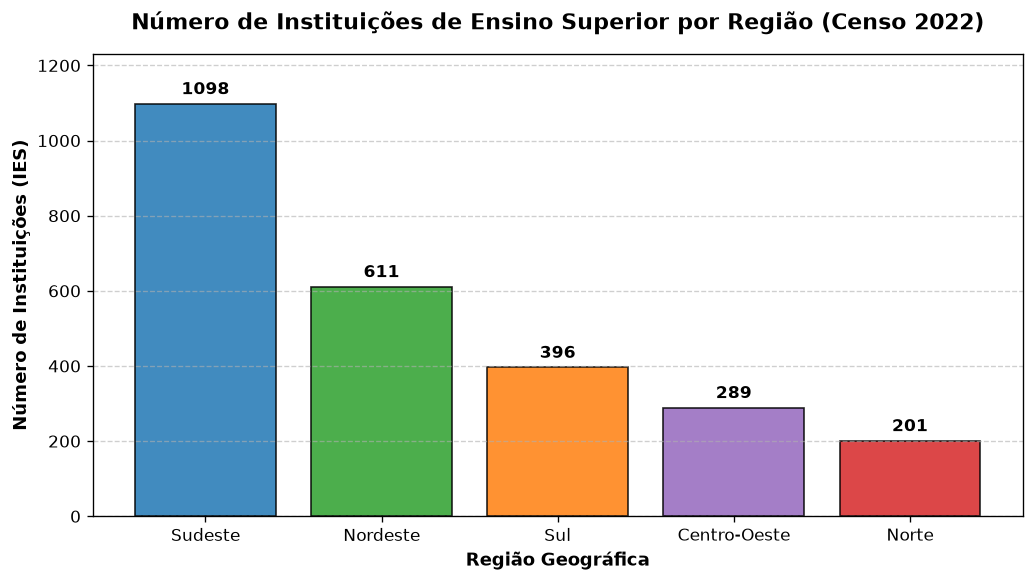

In [2]:
# 1. Consulta agregada: Contagem de IES por região
pipeline_regiao = [
    {'$group': {'_id': '$NO_REGIAO_IES', 'count': {'$sum': 1}}},
    {'$sort': {'count': -1}}
]
result_regiao = list(collection.aggregate(pipeline_regiao))

# Exibição tabular dos resultados
total_ies = sum(r['count'] for r in result_regiao)
print("Resultado da Agregação - Instituições por Região:")
print(f"{'Região':<18} | {'Quantidade de IES':>18} | {'Percentual (%)':>14}")
print("-" * 56)
for r in result_regiao:
    pct = (r['count'] / total_ies) * 100
    print(f"{r['_id']:<18} | {r['count']:>18} | {pct:>13.2f}%")
print("-" * 56)
print(f"{'TOTAL':<18} | {total_ies:>18} | {'100.00%':>14}")

# Extração para listas e geração do gráfico
regions, counts = zip(*[(r['_id'], r['count']) for r in result_regiao])

plt.figure(figsize=(10, 5))
bars = plt.bar(regions, counts, color=['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728'], edgecolor='black', alpha=0.85)
plt.xlabel('Região Geográfica', fontsize=11, fontweight='bold')
plt.ylabel('Número de Instituições (IES)', fontsize=11, fontweight='bold')
plt.title('Número de Instituições de Ensino Superior por Região (Censo 2022)', fontsize=13, fontweight='bold', pad=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f'{int(yval)}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, max(counts) * 1.12)
plt.show()

--- 
## 3. Consulta Agregada 2: Proporção de Docentes por Gênero

Utilizamos o `aggregate()` agrupando toda a base (`'_id': None`) e somando os campos `QT_DOC_EX_FEMI` (docentes do sexo feminino em exercício) e `QT_DOC_EX_MASC` (docentes do sexo masculino em exercício).

Resultado da Agregação - Docentes por Gênero:
- Total Feminino (QT_DOC_EX_FEMI):     590,530 (52.23%)
- Total Masculino (QT_DOC_EX_MASC):    540,044 (47.77%)
- Soma Geral Consolidada:            1,130,574 (100.00%)


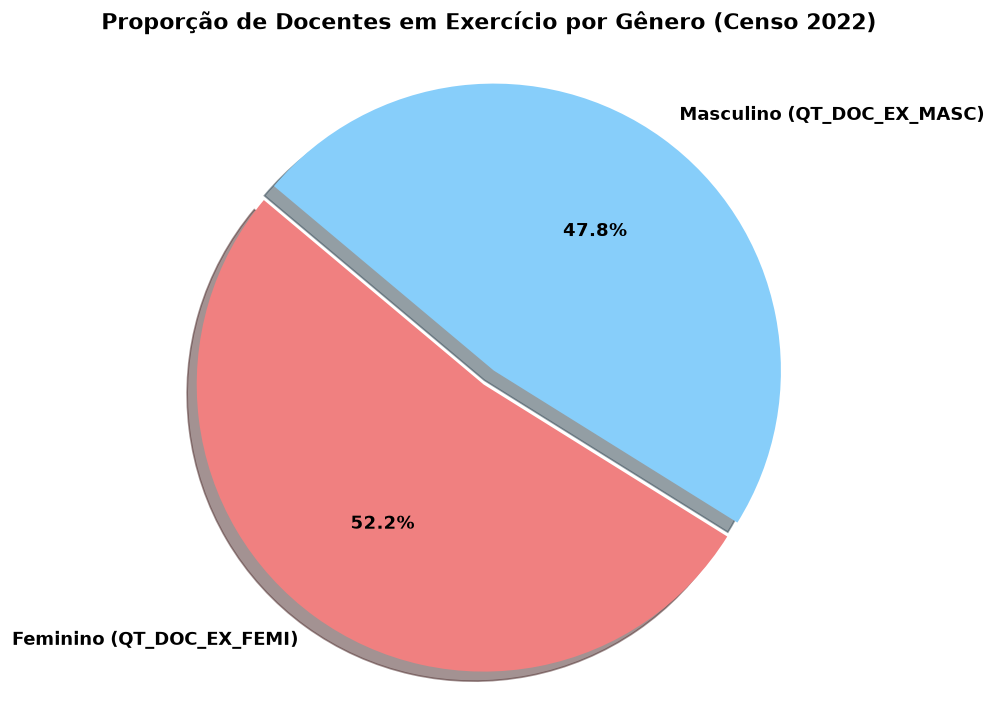

In [3]:
# 2. Consulta agregada: Proporção de docentes por gênero
pipeline_docentes = [
    {'$group': {
        '_id': None,
        'total_fem': {'$sum': '$QT_DOC_EX_FEMI'},
        'total_masc': {'$sum': '$QT_DOC_EX_MASC'}
    }}
]
res_doc = next(collection.aggregate(pipeline_docentes))
total_fem = res_doc['total_fem']
total_masc = res_doc['total_masc']
total_doc = total_fem + total_masc

print("Resultado da Agregação - Docentes por Gênero:")
print(f"- Total Feminino (QT_DOC_EX_FEMI):  {total_fem:>10,} ({total_fem/total_doc*100:.2f}%)")
print(f"- Total Masculino (QT_DOC_EX_MASC): {total_masc:>10,} ({total_masc/total_doc*100:.2f}%)")
print(f"- Soma Geral Consolidada:           {total_doc:>10,} (100.00%)")

# Plotando gráfico de setores (Pie Chart)
labels = ['Feminino (QT_DOC_EX_FEMI)', 'Masculino (QT_DOC_EX_MASC)']
sizes = [total_fem, total_masc]
colors = ['lightcoral', 'lightskyblue']
explode = (0.06, 0)

plt.figure(figsize=(8, 7))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140, textprops={'fontsize': 11, 'fontweight': 'bold'})
plt.axis('equal')
plt.title('Proporção de Docentes em Exercício por Gênero (Censo 2022)', fontsize=13, fontweight='bold', pad=15)
plt.show()

--- 
## 4. Consulta Agregada 3: Número de Instituições por Estado (`NO_UF_IES`)

Agrupamos os documentos pelo campo `$NO_UF_IES` para contabilizar a presença de Instituições de Ensino Superior em cada uma das 27 Unidades da Federação, ordenando do estado com maior número de IES para o menor.

Resultado da Agregação - Instituições por Estado (NO_UF_IES):
Ordem  | Estado (UF)            |  Quantidade de IES
----------------------------------------------------
1      | Sao Paulo              |                585
2      | Minas Gerais           |                312
3      | Parana                 |                172
4      | Bahia                  |                153
5      | Rio de Janeiro         |                130
6      | Goias                  |                118
7      | Rio Grande do Sul      |                118
8      | Pernambuco             |                114
9      | Santa Catarina         |                106
10     | Ceara                  |                103
11     | Para                   |                 78
12     | Mato Grosso            |                 72
13     | Espirito Santo         |                 71
14     | Distrito Federal       |                 66
15     | Maranhao               |                 66
16     | Piaui                  |    

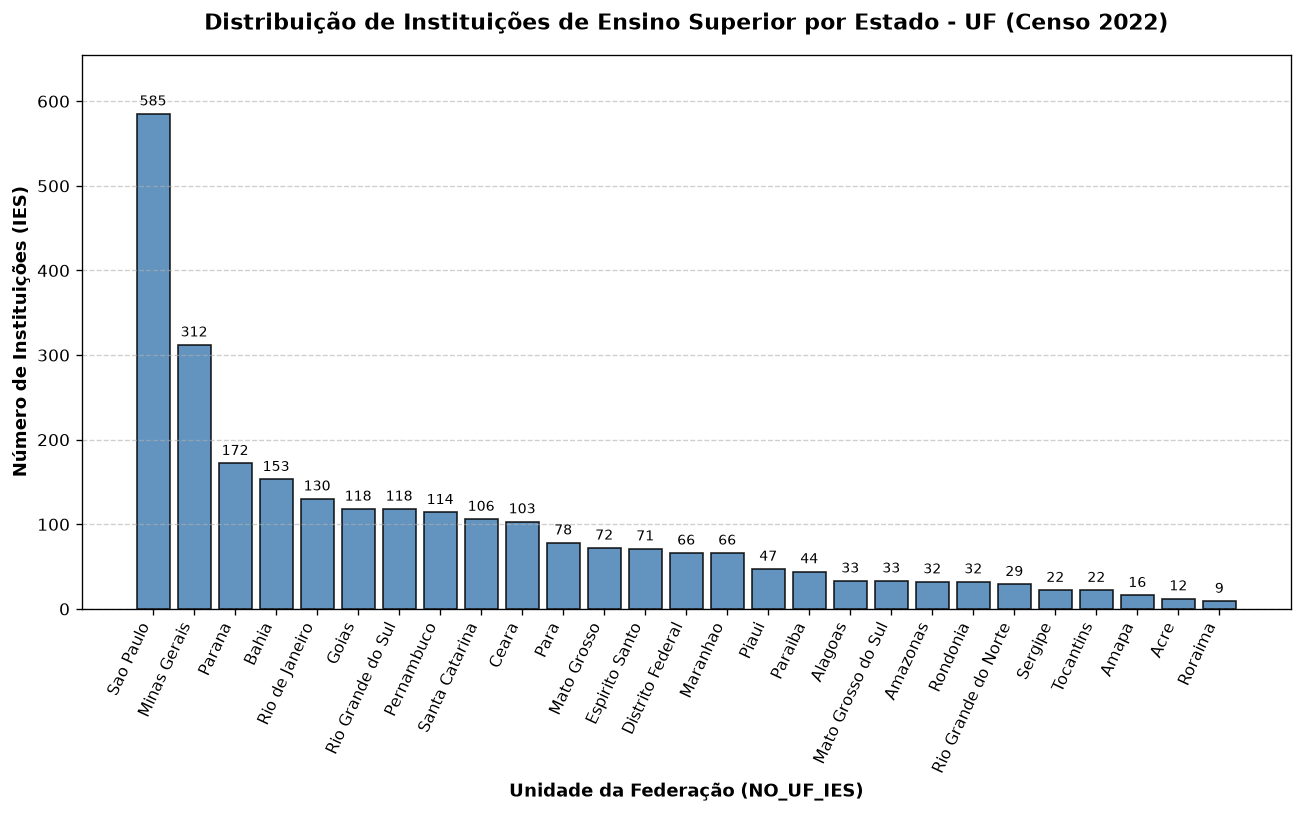

In [4]:
# 3. Consulta agregada: Contagem de IES por Estado (NO_UF_IES)
pipeline_uf = [
    {'$group': {'_id': '$NO_UF_IES', 'count': {'$sum': 1}}},
    {'$sort': {'count': -1}}
]
result_uf = list(collection.aggregate(pipeline_uf))

print("Resultado da Agregação - Instituições por Estado (NO_UF_IES):")
print(f"{'Ordem':<6} | {'Estado (UF)':<22} | {'Quantidade de IES':>18}")
print("-" * 52)
for idx, r in enumerate(result_uf, 1):
    print(f"{idx:<6} | {r['_id']:<22} | {r['count']:>18}")
print("-" * 52)

states, counts_uf = zip(*[(r['_id'], r['count']) for r in result_uf])
print(f"Total de Unidades da Federação: {len(states)} | Total de IES: {sum(counts_uf)}")

# Plotando gráfico de barras por UF
plt.figure(figsize=(13, 6))
bars = plt.bar(states, counts_uf, color='steelblue', edgecolor='black', alpha=0.85)
plt.xlabel('Unidade da Federação (NO_UF_IES)', fontsize=11, fontweight='bold')
plt.ylabel('Número de Instituições (IES)', fontsize=11, fontweight='bold')
plt.title('Distribuição de Instituições de Ensino Superior por Estado - UF (Censo 2022)', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=65, ha='right', fontsize=9.5)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 6, f'{int(yval)}', ha='center', va='bottom', fontsize=8.5)

plt.ylim(0, max(counts_uf) * 1.12)
plt.tight_layout()
plt.show()

--- 
## 5. Conclusões da Análise Exploratória

1. **Concentração Regional:** A região **Sudeste** concentra **42,31% (1.098)** das Instituições de Ensino Superior do país, seguida pelo **Nordeste (23,55% - 611)** e **Sul (15,26% - 396)**.
2. **Distribuição por UF:** Apenas os estados de **São Paulo (585 IES)** e **Minas Gerais (312 IES)** respondem por mais de um terço de todas as instituições brasileiras, enquanto estados da região Norte como **Roraima (9)**, **Acre (12)** e **Amapá (16)** possuem os menores quantitativos.
3. **Proporção por Gênero:** A soma agregada dos campos `QT_DOC_EX_FEMI` e `QT_DOC_EX_MASC` evidencia uma distribuição equilibrada entre docentes do gênero feminino (**52,23%**) e masculino (**47,77%**).